In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline

print('Libraries loaded.')

Libraries loaded.


In [2]:
# =============================================================================
# 2. LOAD & PREPARE DATA
# =============================================================================
FILE_PATH = '../data/processed/final_training_dataset.csv'

df = pd.read_csv(FILE_PATH)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

TARGET_COL   = 'energy_kwh.1'
DROP_COLS    = ['timestamp', TARGET_COL,
                'tx_wind', 'dd_heat']     # zero-coefficient cols from baseline — dropped

feature_cols = [
    col for col in df.select_dtypes(include=[np.number]).columns
    if col not in DROP_COLS
]

X = df[feature_cols]
y = df[TARGET_COL]

print(f'Rows        : {len(df)}')
print(f'Features    : {len(feature_cols)} → {feature_cols}')
print(f'Target      : {TARGET_COL}')

Rows        : 2129
Features    : 19 → ['temp_hi', 'bar', 'dew_in', 'temp_in', 'pt_dew', 'index_thsw', 'index_uv', 'hum_out', 'dose_uv', 'temp_low', 'density_in_air', 'rain', 'run_wind', 'emc_in', 'rate_rain', 'out_temp', 'speed_hi', 'speed_wind', 'hum_in']
Target      : energy_kwh.1


In [3]:
# =============================================================================
# 3. TRAIN-TEST SPLIT  (80 / 20)  — same seed as baseline for fair comparison
# =============================================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Train rows : {X_train.shape[0]}')
print(f'Test  rows : {X_test.shape[0]}')

Train rows : 1703
Test  rows : 426


In [4]:
# =============================================================================
# 4. DEGREE SELECTION — compare degree 1 (baseline), 2, and 3
#
# Pipeline per degree:
#   Step 1 — PolynomialFeatures  : creates x², x³, x_i * x_j terms
#   Step 2 — StandardScaler      : normalises the expanded feature set
#   Step 3 — LinearRegression    : fits OLS on the scaled poly features
#
# 5-fold cross-validation R² used to pick the best degree
# (avoids overfitting to a single train/test split)
# =============================================================================
degrees      = [1, 2, 3]
degree_stats = []

for deg in degrees:
    pipe = Pipeline([
        ('poly',   PolynomialFeatures(degree=deg, include_bias=False)),
        ('scaler', StandardScaler()),
        ('model',  LinearRegression())
    ])

    # 5-fold CV on training data only
    cv_r2 = cross_val_score(pipe, X_train, y_train,
                            cv=5, scoring='r2').mean()

    # Fit on full train set to get test metrics
    pipe.fit(X_train, y_train)
    y_pred     = pipe.predict(X_test)
    test_r2    = r2_score(y_test, y_pred)
    test_mae   = mean_absolute_error(y_test, y_pred)
    test_rmse  = np.sqrt(mean_squared_error(y_test, y_pred))
    n_features = pipe.named_steps['poly'].n_output_features_

    degree_stats.append({
        'Degree'          : deg,
        'CV R² (train)'   : round(cv_r2,   4),
        'Test R²'         : round(test_r2,  4),
        'Test MAE'        : round(test_mae,  4),
        'Test RMSE'       : round(test_rmse, 4),
        'Num Features'    : n_features
    })
    print(f'Degree {deg} | CV R²={cv_r2:.4f} | Test R²={test_r2:.4f} | '
          f'RMSE={test_rmse:.4f} | Features={n_features}')

stats_df = pd.DataFrame(degree_stats)
print('\nDegree Comparison Table:')
print(stats_df.to_string(index=False))

Degree 1 | CV R²=0.4693 | Test R²=0.4454 | RMSE=51.0849 | Features=19
Degree 2 | CV R²=-3.5904 | Test R²=-36.9981 | RMSE=422.8661 | Features=209
Degree 3 | CV R²=-746605525.5096 | Test R²=-24141473267136.2695 | RMSE=337057363.5505 | Features=1539

Degree Comparison Table:
 Degree  CV R² (train)       Test R²     Test MAE    Test RMSE  Num Features
      1   4.693000e-01  4.454000e-01 3.741210e+01 5.108490e+01            19
      2  -3.590400e+00 -3.699810e+01 5.653770e+01 4.228661e+02           209
      3  -7.466055e+08 -2.414147e+13 1.639836e+07 3.370574e+08          1539


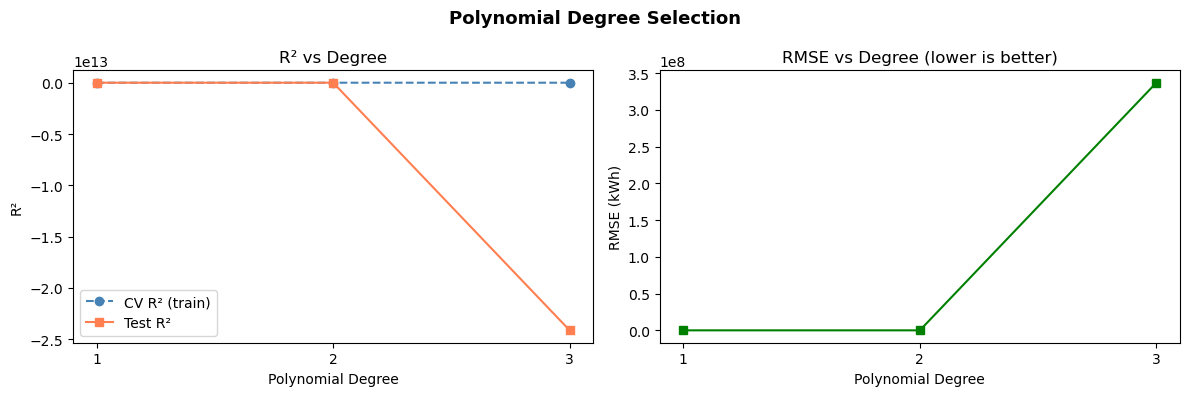

In [5]:
# 5. PLOT — R² and RMSE across degrees
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Polynomial Degree Selection', fontsize=13, fontweight='bold')

axes[0].plot(stats_df['Degree'], stats_df['CV R² (train)'], 'o--',
             color='steelblue', label='CV R² (train)')
axes[0].plot(stats_df['Degree'], stats_df['Test R²'], 's-',
             color='coral', label='Test R²')
axes[0].set_xlabel('Polynomial Degree')
axes[0].set_ylabel('R²')
axes[0].set_title('R² vs Degree')
axes[0].legend()
axes[0].set_xticks(degrees)

axes[1].plot(stats_df['Degree'], stats_df['Test RMSE'], 's-',
             color='green')
axes[1].set_xlabel('Polynomial Degree')
axes[1].set_ylabel('RMSE (kWh)')
axes[1].set_title('RMSE vs Degree (lower is better)')
axes[1].set_xticks(degrees)

plt.tight_layout()
plt.savefig('../outputs/figures/degree_selection.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
# 6. TRAIN FINAL MODEL ON BEST DEGREE
# Best degree = highest Test R² WITHOUT large gap vs CV R²
# (large gap = overfitting)
BEST_DEGREE = int(stats_df.loc[stats_df['Test R²'].idxmax(), 'Degree'])
print(f'Auto-selected best degree : {BEST_DEGREE}')

# Build final pipeline
poly_transformer = PolynomialFeatures(degree=BEST_DEGREE, include_bias=False)
scaler           = StandardScaler()
model            = LinearRegression()

# Fit step by step (so we can inspect each stage)
X_train_poly   = poly_transformer.fit_transform(X_train)
X_test_poly    = poly_transformer.transform(X_test)

X_train_scaled = scaler.fit_transform(X_train_poly)
X_test_scaled  = scaler.transform(X_test_poly)

model.fit(X_train_scaled, y_train)

poly_feature_names = poly_transformer.get_feature_names_out(feature_cols)
print(f'Expanded feature count : {len(poly_feature_names)}')
print('Model trained.')

Auto-selected best degree : 1
Expanded feature count : 19
Model trained.


In [7]:
# 7. EVALUATION — compare Polynomial vs Baseline side by side
y_train_pred = model.predict(X_train_scaled)
y_test_pred  = model.predict(X_test_scaled)

train_r2  = r2_score(y_train, y_train_pred)
test_r2   = r2_score(y_test,  y_test_pred)
test_mae  = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

# Error % = RMSE as % of mean target
mean_target      = y_test.mean()
error_pct        = (test_rmse / mean_target) * 100

# Baseline values from your earlier run (update if different)
baseline_r2   = 0.445
baseline_rmse = None   # set to your actual baseline RMSE if known

print('=' * 50)
print(f'  Polynomial Degree      : {BEST_DEGREE}')
print(f'  Expanded Features      : {len(poly_feature_names)}')
print('─' * 50)
print(f'  R²   — Train           : {train_r2:.4f}')
print(f'  R²   — Test            : {test_r2:.4f}   (baseline: {baseline_r2})')
print(f'  MAE  — Test            : {test_mae:.4f} kWh')
print(f'  RMSE — Test            : {test_rmse:.4f} kWh')
print(f'  Error % (RMSE/mean)    : {error_pct:.2f}%')
print(f'  R² improvement         : +{test_r2 - baseline_r2:.4f} over baseline')
print('=' * 50)

  Polynomial Degree      : 1
  Expanded Features      : 19
──────────────────────────────────────────────────
  R²   — Train           : 0.4923
  R²   — Test            : 0.4454   (baseline: 0.445)
  MAE  — Test            : 37.4121 kWh
  RMSE — Test            : 51.0849 kWh
  Error % (RMSE/mean)    : 32.96%
  R² improvement         : +0.0004 over baseline


In [8]:
# =============================================================================
# 8. TOP POLYNOMIAL FEATURE COEFFICIENTS
# =============================================================================
coeff_df = (
    pd.DataFrame({
        'Feature'    : poly_feature_names,
        'Coefficient': model.coef_
    })
    .assign(Abs_Coeff=lambda d: d['Coefficient'].abs())
    .sort_values('Abs_Coeff', ascending=False)
    .drop(columns='Abs_Coeff')
    .reset_index(drop=True)
)

print(f'Intercept : {model.intercept_:.4f}\n')
print('Top 25 Feature Coefficients (by absolute value):')
print(coeff_df.head(25).to_string(index=False))

Intercept : 156.2813

Top 25 Feature Coefficients (by absolute value):
       Feature  Coefficient
       temp_in  -109.656469
       temp_hi    67.930610
        hum_in   -31.059082
      temp_low    23.821855
        emc_in    20.657170
    index_thsw    17.495159
       hum_out    15.934993
          rain    12.380569
       dose_uv    11.056203
      out_temp    10.024407
      index_uv    -8.143531
density_in_air    -7.529494
           bar     6.751071
      run_wind     6.401831
     rate_rain    -6.250335
      speed_hi     5.945751
        pt_dew    -3.565305
    speed_wind    -3.510757
        dew_in    -1.379599


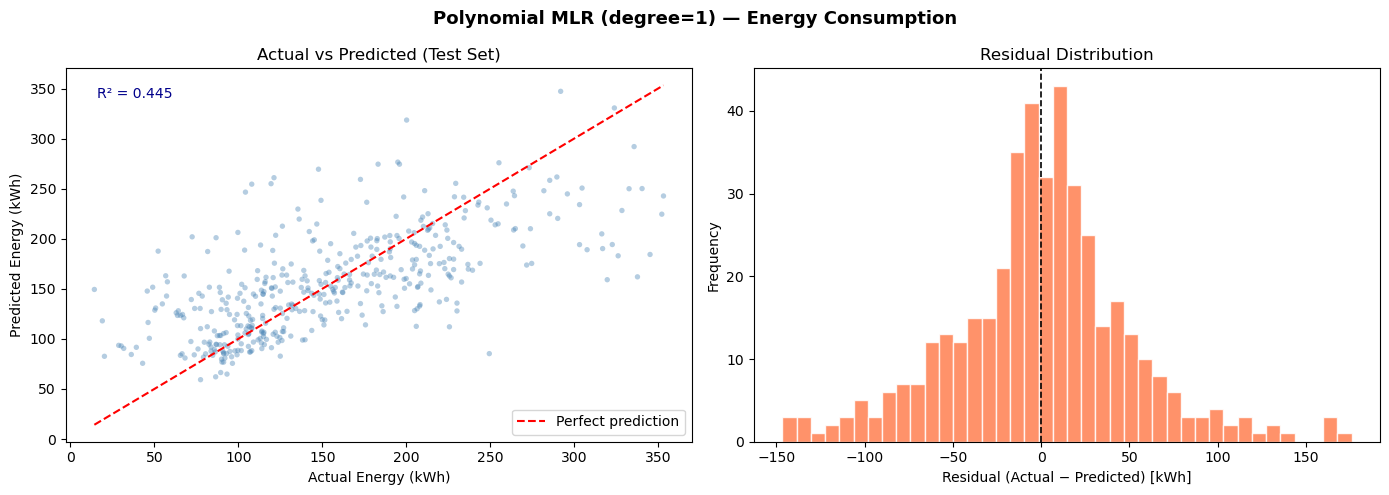

In [9]:
# =============================================================================
# 9. DIAGNOSTIC PLOTS (same layout as baseline — for direct comparison)
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f'Polynomial MLR (degree={BEST_DEGREE}) — Energy Consumption',
             fontsize=13, fontweight='bold')

# Plot 1 — Actual vs Predicted
ax1 = axes[0]
ax1.scatter(y_test, y_test_pred, alpha=0.4, s=15,
            color='steelblue', edgecolors='none')
lim = [min(y_test.min(), y_test_pred.min()),
       max(y_test.max(), y_test_pred.max())]
ax1.plot(lim, lim, 'r--', linewidth=1.5, label='Perfect prediction')
ax1.set_xlabel('Actual Energy (kWh)')
ax1.set_ylabel('Predicted Energy (kWh)')
ax1.set_title('Actual vs Predicted (Test Set)')
ax1.annotate(f'R² = {test_r2:.3f}', xy=(0.05, 0.92),
             xycoords='axes fraction', fontsize=10, color='darkblue')
ax1.legend()

# Plot 2 — Residuals
residuals = y_test.values - y_test_pred
ax2 = axes[1]
ax2.hist(residuals, bins=40, color='coral', edgecolor='white', alpha=0.85)
ax2.axvline(0, color='black', linestyle='--', linewidth=1.2)
ax2.set_xlabel('Residual (Actual − Predicted) [kWh]')
ax2.set_ylabel('Frequency')
ax2.set_title('Residual Distribution')

plt.tight_layout()
plt.savefig('../outputs/figures/poly_mlr_plots.png', dpi=150, bbox_inches='tight')
plt.show()

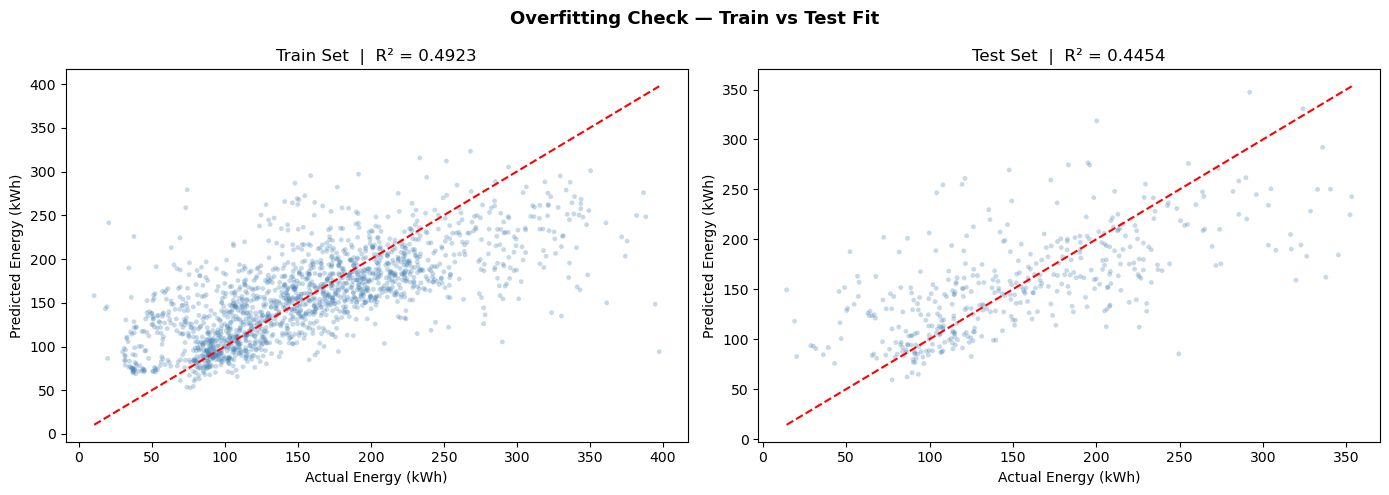

Train R² : 0.4923
Test  R² : 0.4454
Gap      : 0.0468  →  Good — no significant overfitting.


In [10]:
# =============================================================================
# 10. OVERFITTING CHECK — Actual vs Predicted for Train set too
#     If train R² >> test R², the model is overfitting.
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Overfitting Check — Train vs Test Fit', fontsize=13, fontweight='bold')

for ax, y_true, y_pred, label, r2 in [
    (axes[0], y_train, y_train_pred, 'Train', train_r2),
    (axes[1], y_test,  y_test_pred,  'Test',  test_r2)
]:
    ax.scatter(y_true, y_pred, alpha=0.3, s=12,
               color='steelblue', edgecolors='none')
    lim = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax.plot(lim, lim, 'r--', linewidth=1.5)
    ax.set_xlabel(f'Actual Energy (kWh)')
    ax.set_ylabel('Predicted Energy (kWh)')
    ax.set_title(f'{label} Set  |  R² = {r2:.4f}')

plt.tight_layout()
plt.savefig('../outputs/figures/overfit_check.png', dpi=150, bbox_inches='tight')
plt.show()

gap = train_r2 - test_r2
print(f'Train R² : {train_r2:.4f}')
print(f'Test  R² : {test_r2:.4f}')
print(f'Gap      : {gap:.4f}', end='  →  ')
if gap < 0.05:
    print('Good — no significant overfitting.')
elif gap < 0.15:
    print('Mild overfitting. Consider Ridge regression.')
else:
    print('Overfitting detected. Use Ridge / Lasso or reduce degree.')

In [11]:
# =============================================================================
# 11. PREDICTION FUNCTION
#     User provides raw weather values → model returns predicted energy in kWh
#     The function applies the SAME poly expansion + scaler as training.
# =============================================================================

def predict_energy(input_dict: dict) -> float:
    """
    Predict hourly energy consumption from user-supplied weather parameters.

    Parameters
    ----------
    input_dict : dict
        Raw weather values. Required keys (19 features):
        temp_hi, bar, dew_in, temp_in, pt_dew, index_thsw, index_uv,
        hum_out, dose_uv, temp_low, density_in_air, rain, run_wind,
        emc_in, rate_rain, out_temp, speed_hi, speed_wind, hum_in

    Returns
    -------
    float
        Predicted energy consumption in kWh.

    Example
    -------
    >>> result = predict_energy({
    ...     'temp_hi': 30.4, 'bar': 29.8, 'dew_in': 21.4, 'temp_in': 25.7,
    ...     'pt_dew': 26.0, 'index_thsw': 43.6, 'index_uv': 3.7,
    ...     'hum_out': 76.0, 'dose_uv': 0.4, 'temp_low': 30.7,
    ...     'density_in_air': 0.0716, 'rain': 0.0, 'run_wind': 2.7,
    ...     'emc_in': 15.0, 'rate_rain': 0.0, 'out_temp': 30.7,
    ...     'speed_hi': 19.3, 'speed_wind': 10.9, 'hum_in': 77.3
    ... })
    >>> print(result)  # e.g. 163.42
    """
    # Step 1 — Raw input → DataFrame with correct column order
    input_df = pd.DataFrame([input_dict])[feature_cols]

    # Step 2 — Apply polynomial expansion (same degree as training)
    input_poly = poly_transformer.transform(input_df)

    # Step 3 — Scale using the fitted scaler
    input_scaled = scaler.transform(input_poly)

    # Step 4 — Predict
    prediction = model.predict(input_scaled)[0]

    return round(float(prediction), 4)


# ── QUICK TEST — first row of test set ───────────────────────────────────────
sample_input    = {col: float(X_test.iloc[0][col]) for col in feature_cols}
predicted_value = predict_energy(sample_input)
actual_value    = float(y_test.iloc[0])

print('Sample weather input:')
for k, v in sample_input.items():
    print(f'  {k:<20} : {v}')
print(f'\nPredicted energy : {predicted_value} kWh')
print(f'Actual energy    : {actual_value} kWh')
print(f'Absolute error   : {abs(predicted_value - actual_value):.4f} kWh')

Sample weather input:
  temp_hi              : 25.825
  bar                  : 29.87375
  dew_in               : 23.2
  temp_in              : 28.35
  pt_dew               : 24.65
  index_thsw           : 37.25
  index_uv             : 1.725
  hum_out              : 94.0
  dose_uv              : 0.185
  temp_low             : 25.5
  density_in_air       : 0.070975
  rain                 : 0.0
  run_wind             : 2.2125
  emc_in               : 14.09
  rate_rain            : 0.0
  out_temp             : 25.675
  speed_hi             : 17.3
  speed_wind           : 8.85
  hum_in               : 74.0

Predicted energy : 151.5352 kWh
Actual energy    : 206.75 kWh
Absolute error   : 55.2148 kWh
